# t-SNE / UMAP Embedding

**Family:** Multivariate & ML &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Multivariate & ML:* Explore many variables at once and explain or diagnose statistical and machine-learning models.

## Design purpose

A non-linear projection that places observations with similar profiles near each other in 2-D. It shows local neighbourhoods, clusters and how well labelled groups separate in high-dimensional data.

## When to use

- Explore whether high-dimensional samples (patients, cells, documents) form clusters
- Check whether known labels correspond to natural groupings in the features
- Present single-cell, omics or embedding-model output

## Avoid when

- You want to read distances or sizes between clusters (t-SNE does not preserve them)
- The axes would be interpreted as variables (they have no meaning)
- There are few variables, or a linear method such as PCA already shows the structure

## Alternatives

- PCA biplot (linear, interpretable axes)
- UMAP (umap-learn package; faster, keeps more global structure)
- Clustered heatmap

## Design tips

- Hide the tick labels; the coordinates are arbitrary
- Try several perplexity values and random seeds before trusting a cluster
- Standardize the features first

## Example

The real Breast Cancer Wisconsin (Diagnostic) dataset bundled with scikit-learn (load_breast_cancer). It has 569 tumours, each with 30 cell-nucleus measurements and a benign/malignant diagnosis.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import load_breast_cancer
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

### Data

In [2]:
bc = load_breast_cancer(as_frame=True)
Z = StandardScaler().fit_transform(bc.data)
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(Z)
df = pd.DataFrame(emb, columns=["dim1", "dim2"])
df["diagnosis"] = bc.target.map({0: "Malignant", 1: "Benign"})
df["diagnosis"].value_counts()

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64

### Plot

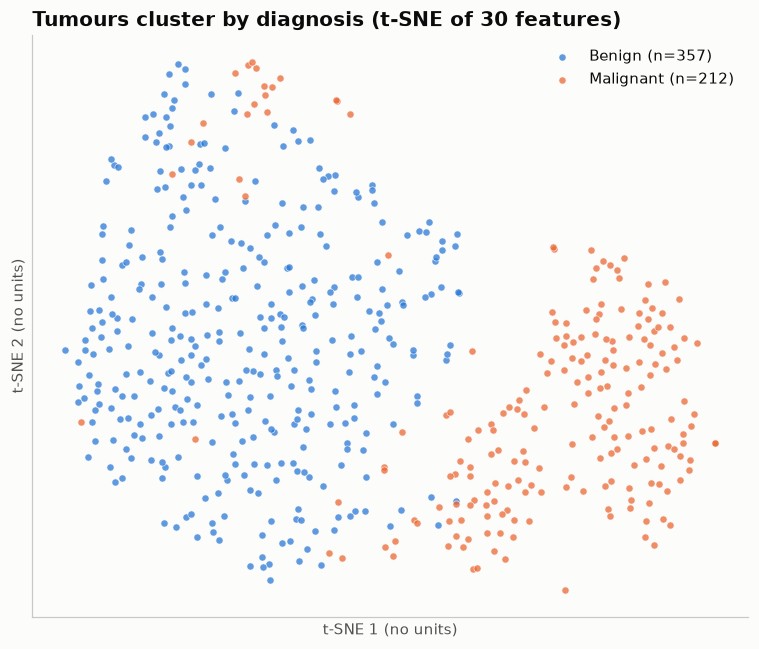

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
for color, label in zip(PALETTE, ["Benign", "Malignant"]):
    g = df[df["diagnosis"] == label]
    ax.scatter(g["dim1"], g["dim2"], s=22, alpha=0.75, color=color,
               edgecolor="#fcfcfb", linewidth=0.5, label=f"{label} (n={len(g)})")
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.set_xlabel("t-SNE 1 (no units)")
ax.set_ylabel("t-SNE 2 (no units)")
ax.set_title("Tumours cluster by diagnosis (t-SNE of 30 features)")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

## How to read it

Each dot is a tumour. Benign and malignant tumours occupy mostly separate regions, so the 30 measurements carry strong diagnostic signal. The handful of dots inside the other group's region are the cases a classifier will find hardest.

---
Standalone script: [`tsne_embedding.py`](tsne_embedding.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)